# Numerical excersises 9 

### The Traveling Salesman Problem

The traveling salesman problem (TSP) consists of a salesman and a set of $N$ cities with positions $\vec{c}_i$. The salesman **has to visit each one of the cities starting from a certain one (e.g. the hometown) and returning to the same city**. The challenge of the problem is that the traveling salesman wants to **minimize the total length of the trip**.

Consider now the ordered sequence of cities, $\vec{c}_1, \vec{c}_2, \dots, \vec{c}_N$, which goes from city 1 to the n$^{th}$ city. The path that minimizes the following loss/cost function:

$$
L^{(2)}(\vec{x}_1, \vec{x}_2, \dots, \vec{x}_N) = \sum_{i=1}^{N} |\vec{x}_i-\vec{x}_{i+1}|^2
$$

or 
$$
L^{(1)}(\vec{x}_1, \vec{x}_2, \dots, \vec{x}_N) = \sum_{i=1}^{N} |\vec{x}_i-\vec{x}_{i+1}|
$$


(with $\vec{x}_{N+1}=\vec{x}_1$) is one particular permutation, P, of the ordered sequence of cities $\vec{c}_1, \vec{c}_2, \dots, \vec{c}_N$, i.e. 

$$
\vec{x}_1, \vec{x}_2, \dots, \vec{x}_N = \vec{c}_{P1}, \vec{c}_{P2}, \dots, \vec{c}_{PN}
$$

Note also that any particular permutation of the ordered sequence of cities can be obtained from the combination of many simple permutations among pairs of cities.

We can express a possible path via a 1D vector whose elements, from the first to the last, are integers that represents the cities in the order in which the salesman would visit them; for example for $N=5$ cities one possible path is represented by the vector:

$$
\left[ 1, 3, 5, 4, 2 \right]
$$

**Alteratively**, we can express a possible path also via a configuration of a $N\times N$ 2D *Ising-like* model with the following bonds:
1. any row must have one and at most one up spin
2. any column must have one and at most one up spin,

all the other spins are down.

We can represent such a configuration with a $N\times N$ matrix whose elements are 1 (spin up) or 0 (spin down); for example, in the case of a TSP with 5 cities:
$$
\begin{bmatrix}
1 & 0 & 0 & 0 & 0\\
0 & 0 & 0 & 0 & 1\\
0 & 1 & 0 & 0 & 0\\
0 & 0 & 0 & 1 & 0\\
0 & 0 & 1 & 0 & 0\\
\end{bmatrix}
$$

You can interpret this matrix in the following way:
- column index represents time of visit: first colum = first visit, etc.
- row index represents the ordered sequence of cities: first row = first city, etc.

the previous matrix thus refers to the following sequence:

$$
\vec{x}_1, \vec{x}_2, \vec{x}_3, \vec{x}_4, \vec{x}_5 = 
\vec{c}_{1}, \vec{c}_{3}, \vec{c}_{5}, \vec{c}_{4}, \vec{c}_{2}
$$

and thus to the following *cost* of the path:

$$
L^{(2)}(\vec{x}_1, \dots, \vec{x}_5) = 
|\vec{c}_1-\vec{c}_3|^2 + |\vec{c}_3-\vec{c}_5|^2 + |\vec{c}_5-\vec{c}_4|^2 +
|\vec{c}_4-\vec{c}_2|^2 + |\vec{c}_2-\vec{c}_1|^2
$$

or
$$
L^{(1)}(\vec{x}_1, \dots, \vec{x}_5) = 
|\vec{c}_1-\vec{c}_3| + |\vec{c}_3-\vec{c}_5| + |\vec{c}_5-\vec{c}_4| +
|\vec{c}_4-\vec{c}_2| + |\vec{c}_2-\vec{c}_1|
$$


Note that, for this *ising-like* representation any particular permutation of the ordered sequence of cities can be obtained by a sequence of multiple pair permutations among rows and/or among columns.

**<span style="color:red">Warm suggestion: by using the 1D representation</span>** (but you can work with the representation you prefer or the one you are able to invent) ...

### Exercise 09.1

Write a code to solve the TSP with a **Genetic** algorithm (GA). Note that you should invent **some** *genetic-mutation* operators and a *genetic-crossover* operator which should preserve the bonds of the problem: the salesman must visit one and only one time every city and must be back to the first city in the end of the path.

Once the data structure of your code is ready, before you start coding your genetic operators, I warmly suggest you to code the creation of the starting population and to code a **check function** that verifies if every *individual* fulfils the bonds. Then check your starting population ... and use your check function every time you create a new individual.

You have to invent also a **selection** operator. 
The fitness and thus the order of the population should be obtained from $L^{(1)}(\vec{x}_1, \vec{x}_2, \dots, \vec{x}_N)$. Once your starting population has been ordered on a fitness basis,
you have 2 possibilities:
1. write a selection operator which obtain the probability to select an individual from $L^{(1)}(\vec{x}_1, \vec{x}_2, \dots, \vec{x}_N)$
2. write a selection operator which simply uses the order in the orderd population with $M$ individuals, e.g. select the individual $j$ with the algorithm: $j= int(M \times r^p)+1$ where $r$ is a uniform random number $r\in[0,1)$ and $p$ a convenient exponent. 

<span style="color:red">Set the first city to always appear at position 1, so as to reduce the degeneration of the shortest route to be 2, which corresponds to walking the shortest route in clockwise and anti-clockwise directions.</span>

Then you can start introducing some *genetic-mutation* operators, for example:
1. pair permutation of cities (except for the first city), e.g. $\left[ 1, 2, 3, 4, 5 \right] \to \left[ 1, 2, 4, 3, 5 \right]$ (At this point you should already have such operator ... how have you generated the starting population?).
2. shift of $+n$ positions for $m$ contiguous cities (except for the first city and $m \lt N-1$), e.g. $\left[ 1, 2, 3, 4, 5 \right] \to \left[ 1, 4, 5, 2, 3 \right] $ for a $+2$ shift of the second and third cities.
3. permutation among $m$ contiguous cities (except for the first city) with other (different!) $m$ contiguous cities ($m<N/2$), e.g. $\left[ 1, 2, 3, 4, 5 \right] \to \left[ 1, 4, 5, 2, 3 \right] $ for a permutation of the second and third cities with the last 2.
4. inversion of the order in which they appear in the path of $m$ cities (except for the first city and $m \le N$), e.g. $\left[ 1, 2, 3, 4, 5 \right] \to \left[ 1, 4, 3, 2, 5 \right]$ for the inversion of the cities from 2 to 4.

Every mutation will have its probability, $p^{(i)}_m$ to be called and typically $p^{(i)}_m < 10\%$, but before to include crossover you can check if the GA is able to perform a good *random search* using only mutation operators (in this case $p^{(i)}$ could be higher than in the previous suggestion).

At this point you can add a *crossover* operator (that fulfils the bonds and that you will call with probability $p^{(i)}_c > 50\%$):

given a selected mother and father, e.g. 
$$
\left[ 1, 2, 3, 4, 5 \right]\\
\left[ 1, 5, 4, 3, 2 \right] 
$$
1. cut their paths at the same position:
$$
\left[ 1, 2, 3 | 4, 5 \right]\\
\left[ 1, 5, 4 | 3, 2 \right] 
$$
2. conserve the first part of the paths:
$$
\left[ 1, 2, 3 | X, Y \right]\\
\left[ 1, 5, 4 | X, Y \right] 
$$
3. complete the paths with the missing cities adding them in the **order** in which they appear in the consort:
$$
\left[ 1, 2, 3 | 5, 4 \right]\\
\left[ 1, 5, 4 | 2, 3 \right] 
$$

Here you are: you have two sons that you can add to the new generation ... and so on!
Apply your code to the optimization of a path among 

- <span style="color:blue">34 cities randomly placed **on** a circumference</span>
- <span style="color:blue">34 cities randomly placed **inside** a square</span>

Show your results via:

- <span style="color:red">a picture of $L^{(1)}$ of the best path and of $\langle L^{(1)}\rangle$, averaged on the best half of the population, as a function of the iterations/generations of your algorithm</span>
- <span style="color:red">a picture of the best path in cartesian coordinates</span>

## **Solution**

For this exercise, the objective is to solve the Traveling Salesman Problem (TSP) using a Genetic Algorithm (GA). Given the complexity and modular nature of evolutionary algorithms, a significant portion of this assignment was dedicated to designing a robust, efficient, and object-oriented C++ architecture.

The code is built around an inheritance structure with a base class and three specialized derived classes, leveraging the Armadillo library (`arma::uvec` and `arma::mat`) for efficient vector and matrix manipulations. 

Below is an overview of the implemented class architecture:

#### 1. `GeneticAlg` (Base Class)
This is the root class that holds the universal static parameters of the simulation (e.g., number of cities, population size, number of generations, mutation and crossover probabilities).
* It provides the static method `load_input()` which reads these parameters once from `input.dat` at runtime, ensuring that all derived classes share the same physical constraints without duplicating memory or requiring manual parameter passing.

#### 2. `Map`
This class handles the spatial configuration of the cities and their mutual distances.
* **Initialization:** It can generate random cities on a unitary circle or within a unitary square (`generate_map()`), or load specific real-world coordinates from a file like the Italian provincial capitals (`read_map_file()`).
* **Distance Matrix:** To drastically optimize the execution time, the map pre-computes an internal $N \times N$ symmetric matrix of all mutual Euclidean distances during initialization (`_distances`). Any subsequent request for a distance simply performs an $O(1)$ matrix lookup via `get_distance()`, avoiding millions of redundant square root operations during the fitness evaluations.

#### 3. `Individual` (The Chromosome)
This class represents a single possible path (a sequence of cities) and its associated cost (the fitness).
* **Representation:** The path is stored as an Armadillo unsigned integer vector (`uvec _genes`), where the first city is strictly fixed at index 0 to break the periodic degeneracy (checked by the `check()` method).
* **Mutations:** It implements the four required genetic mutations: 
  1. `pair_perm()`: swaps two random cities.
  2. `shift_mut()`: shifts a contiguous block of $m$ cities by $n$ positions.
  3. `m_perm()`: swaps two disjoint contiguous blocks of $m$ cities.
  4. `inversion_mut()`: reverses the order of a contiguous sequence of cities.
* To break the directional degeneracy (traveling the same path clockwise vs. counter-clockwise), a `standardize_dir()` method is implemented, which forces the second city index to always be smaller than the last one.

#### 4. `Population`
This class acts as the genetic pool, managing a collection of `Individual` objects (stored in an `arma::field`).
* **Initialization & Sorting:** It generates the initial random population (`initialize()`) and sorts the individuals based on their path length using a custom lambda function and `std::sort` (`sort_individuals()`).
* **Selection:** The `select_individual()` method implements a biased selection operator. It picks individuals using $j = \text{int}(N_{\text{pop}} \times r^p)$, where $r \in [0,1)$ is a uniform random number and $p$ acts as a selection pressure, favoring the best (lowest-index) individuals.
* **Crossover:** The `crossover()` operator generates two children from two parents. It cuts the chromosomes at a random point, copies the first part exactly as in the respective parent, and fills the missing cities in the order they appear in the *other* parent's chromosome, ensuring no city is skipped or duplicated.
* **Evolution:** The `new_gen()` method drives the generational leap. By employing Elitism, it automatically passes the top two individuals to the next generation without modifications. Then, it uses selection and crossover to fill the rest of the pool, finally applying mutations via `mutate_generation()`.

#### 5. Simulation Parameters and Configuration (`input.dat`)

To ensure reproducibility and clean separation between the source code and the experimental setup, all hyperparameters are centralized in an `input.dat` file read at runtime by the `GeneticAlg::load_input()` method. 

For the execution of the Traveling Salesman Problem (both on circular, square, and real-world maps), the following configuration parameters were established:

* **Population Size:** $N_{\text{pop}} = 200$ individuals, providing a sufficiently large genetic pool to explore diverse routing combinations without excessive computational overhead.
* **Number of Generations:** $N_{\text{gens}} = 200$, allowing the system enough evolutionary steps to reach a stable convergence plateau.
* **Selection Pressure:** $p_{\text{selec}} = 2.0$, enforcing a balanced elitist selection where better-performing paths are strongly favored via the quadratic distortion $r^p$, while still preserving genetic diversity.
* **Crossover Probability:** $p_{\text{cross}} = 70\%$, determining the frequency at which parent chromosomes are combined through ordered crossover rather than being directly copied.
* **Mutation Probabilities:** All four mutation operators (`pair_perm`, `shift_mut`, `m_perm`, and `inversion_mut`) are set to an individual probability of $10\%$, ensuring a continuous and unbiased perturbation of the genetic material across generations.

In [3]:
import numpy as np
import matplotlib.pyplot as plt

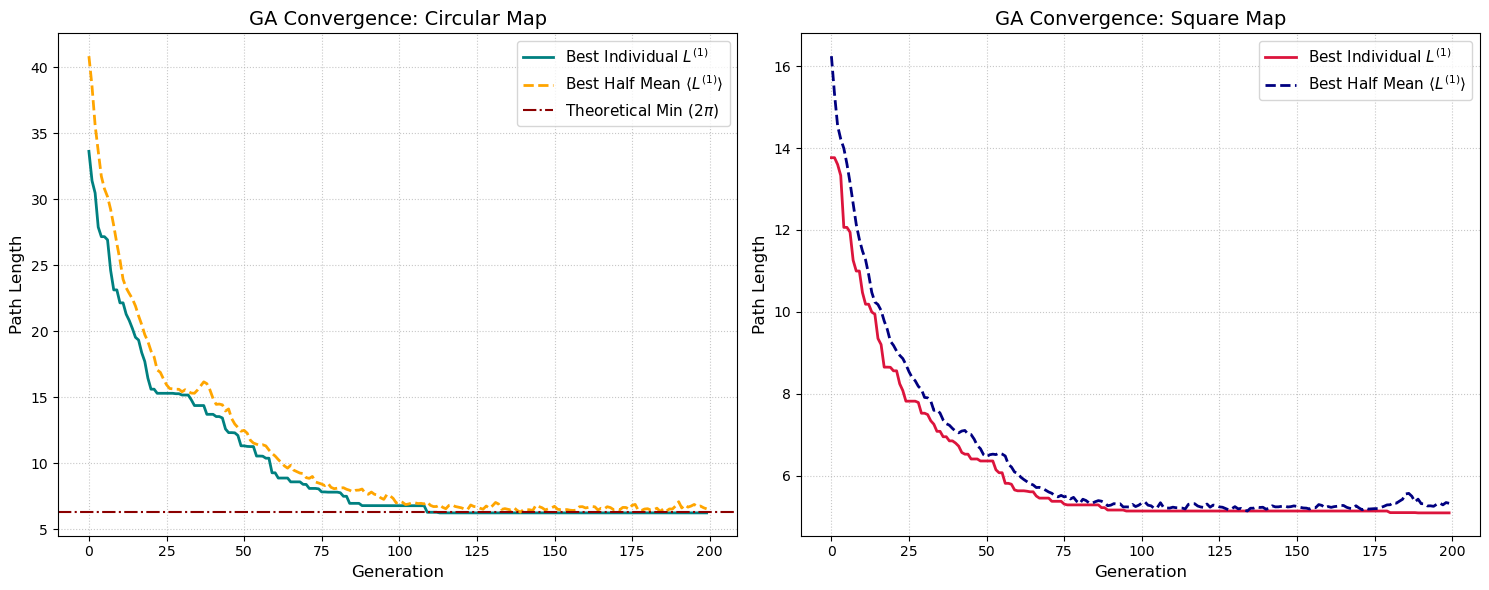

In [9]:
gen_circ, best_circ, mean_circ = np.loadtxt("OUTPUT/circ_output.dat", unpack=True)
gen_sq, best_sq, mean_sq = np.loadtxt("OUTPUT/square_output.dat", unpack=True)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

ax1.plot(gen_circ, best_circ, label=r'Best Individual $L^{(1)}$', color='teal', linewidth=2)
ax1.plot(gen_circ, mean_circ, label=r'Best Half Mean $\langle L^{(1)} \rangle$', color='orange', linestyle='--', linewidth=2)

ax1.set_title('GA Convergence: Circular Map', fontsize=14)
ax1.set_xlabel('Generation', fontsize=12)
ax1.set_ylabel('Path Length', fontsize=12)
ax1.axhline(y=2*np.pi, color='darkred', linestyle='-.', linewidth=1.5, label=r'Theoretical Min ($2\pi$)')
ax1.grid(True, linestyle=':', alpha=0.7)
ax1.legend(fontsize=11)

ax2.plot(gen_sq, best_sq, label=r'Best Individual $L^{(1)}$', color='crimson', linewidth=2)
ax2.plot(gen_sq, mean_sq, label=r'Best Half Mean $\langle L^{(1)} \rangle$', color='navy', linestyle='--', linewidth=2)

ax2.set_title('GA Convergence: Square Map', fontsize=14)
ax2.set_xlabel('Generation', fontsize=12)
ax2.set_ylabel('Path Length', fontsize=12)
ax2.grid(True, linestyle=':', alpha=0.7)
ax2.legend(fontsize=11)

plt.tight_layout()
plt.show()

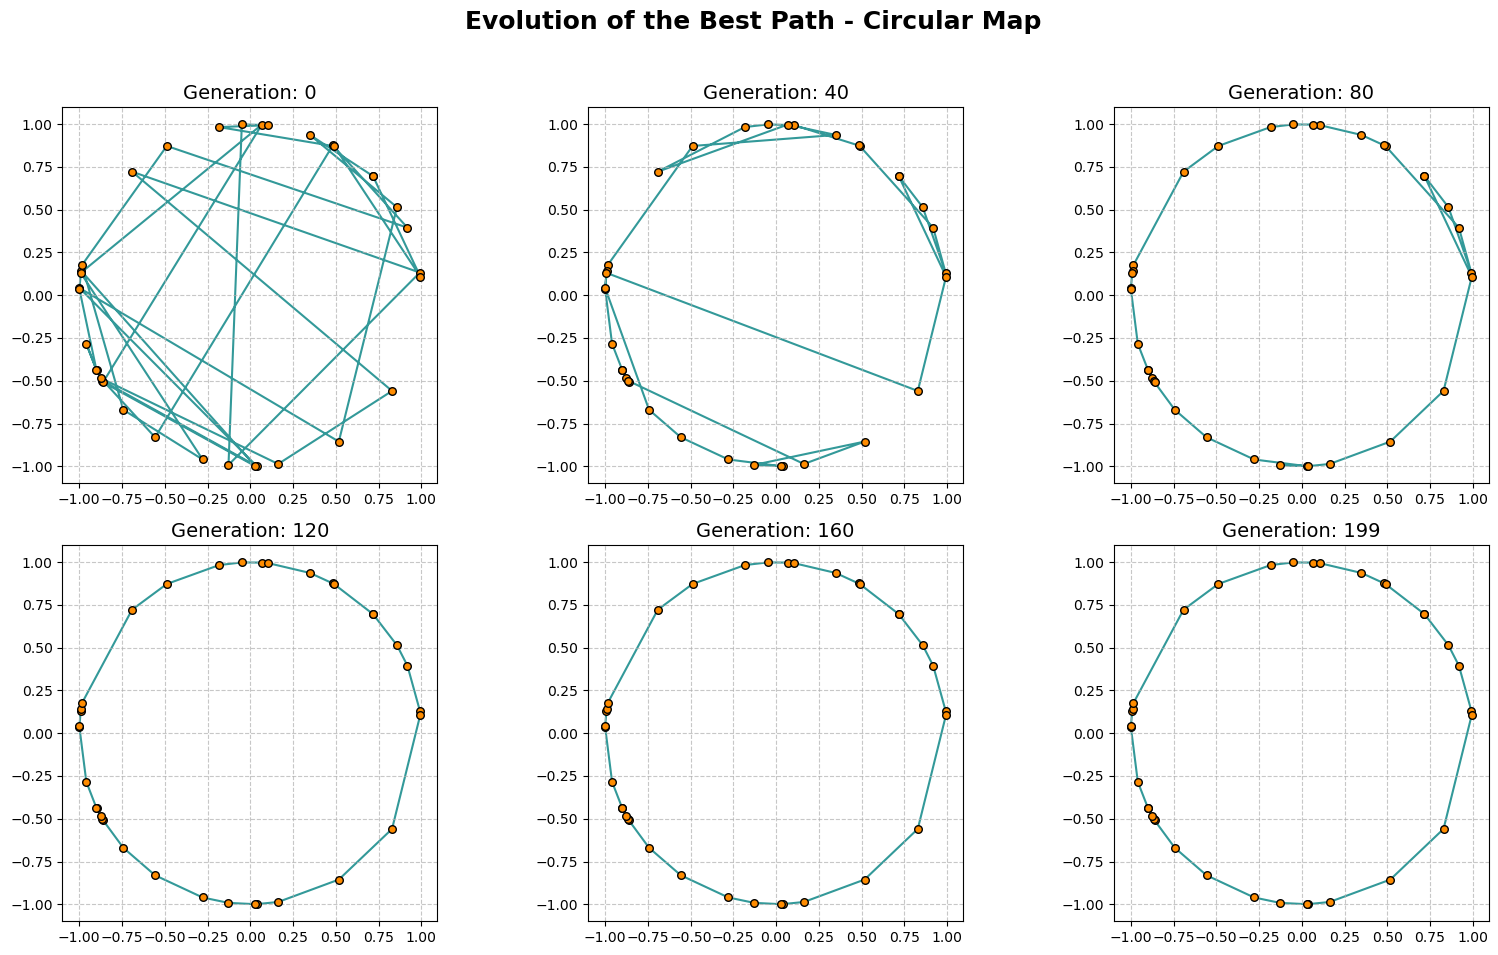

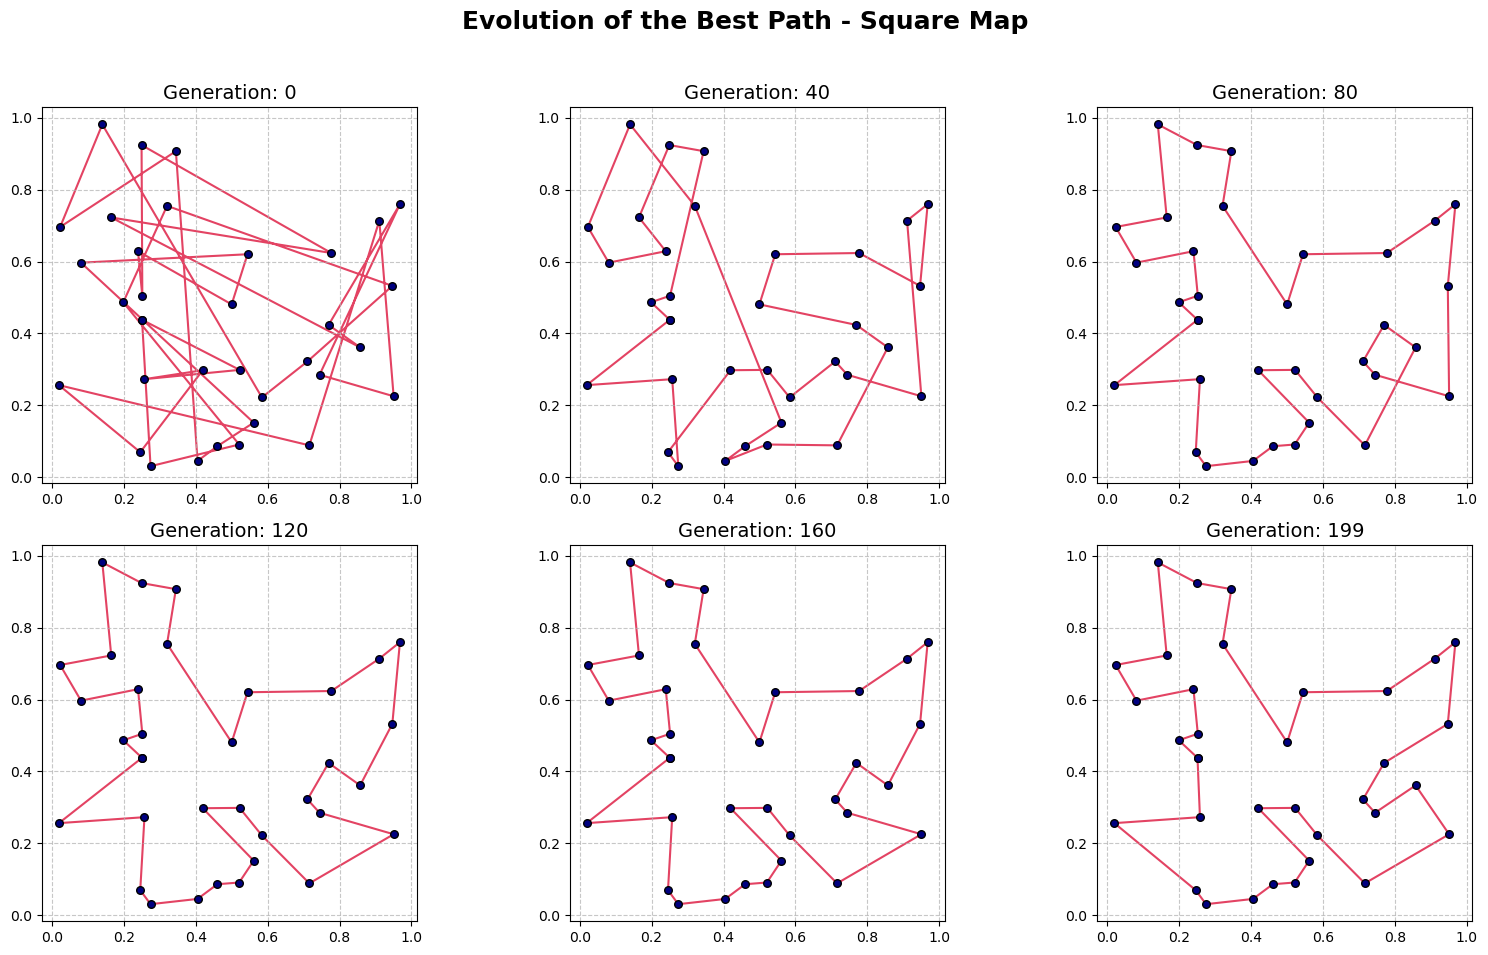

In [7]:
import numpy as np
import matplotlib.pyplot as plt

def plot_six_steps(filename, main_title, line_color, point_color):
    try:
        data = np.loadtxt(filename)
    except FileNotFoundError:
        return

    generations = np.unique(data[:, 0])
    
    if len(generations) >= 6:
        indices = np.linspace(0, len(generations) - 1, 6, dtype=int)
        selected_gens = generations[indices]
    else:
        selected_gens = generations

    fig, axes = plt.subplots(2, 3, figsize=(16, 10))
    fig.suptitle(main_title, fontsize=18, fontweight='bold', y=0.95)
    
    axes = axes.flatten()

    for i, gen in enumerate(selected_gens):
        mask = (data[:, 0] == gen)
        x = data[mask, 1]
        y = data[mask, 2]
        
        axes[i].plot(x, y, color=line_color, linewidth=1.5, alpha=0.8, zorder=1)
        axes[i].scatter(x, y, color=point_color, s=30, zorder=2, edgecolor='black')
        
        axes[i].set_title(f'Generation: {int(gen)}', fontsize=14)
        axes[i].set_aspect('equal')
        axes[i].grid(True, linestyle='--', alpha=0.7)

    for j in range(i + 1, 6):
        axes[j].axis('off')

    plt.tight_layout(rect=[0, 0, 1, 0.93])
    plt.show()

plot_six_steps(
    filename="OUTPUT/circ_history.dat", 
    main_title="Evolution of the Best Path - Circular Map", 
    line_color="teal", 
    point_color="darkorange"
)

plot_six_steps(
    filename="OUTPUT/square_history.dat", 
    main_title="Evolution of the Best Path - Square Map", 
    line_color="crimson", 
    point_color="navy"
)

In both the circular and square geometries, the convergence dynamics exhibit two distinct regimes:

* **Early Generations (Coarse Exploration):** During the initial phase ($\sim 0 - 50$ generations), large-scale topological adjustments take place. The algorithm rapidly eliminates self-intersections, untangles macro-loops, and establishes the broad geometric envelope of the path, leading to a steep, monotonic drop in both $L^{(1)}$ and $\langle L^{(1)} \rangle$.
* **Late Generations (Fine Exploitation):** In the asymptotic regime ($\gtrsim 75$ generations), the optimization shifts entirely toward local refinement. Major structural rewiring ceases, and the algorithm relies predominantly on localized mutations to resolve subtle vertex inversions and minor path permutations, resulting in marginal, incremental improvements until full convergence is attained.

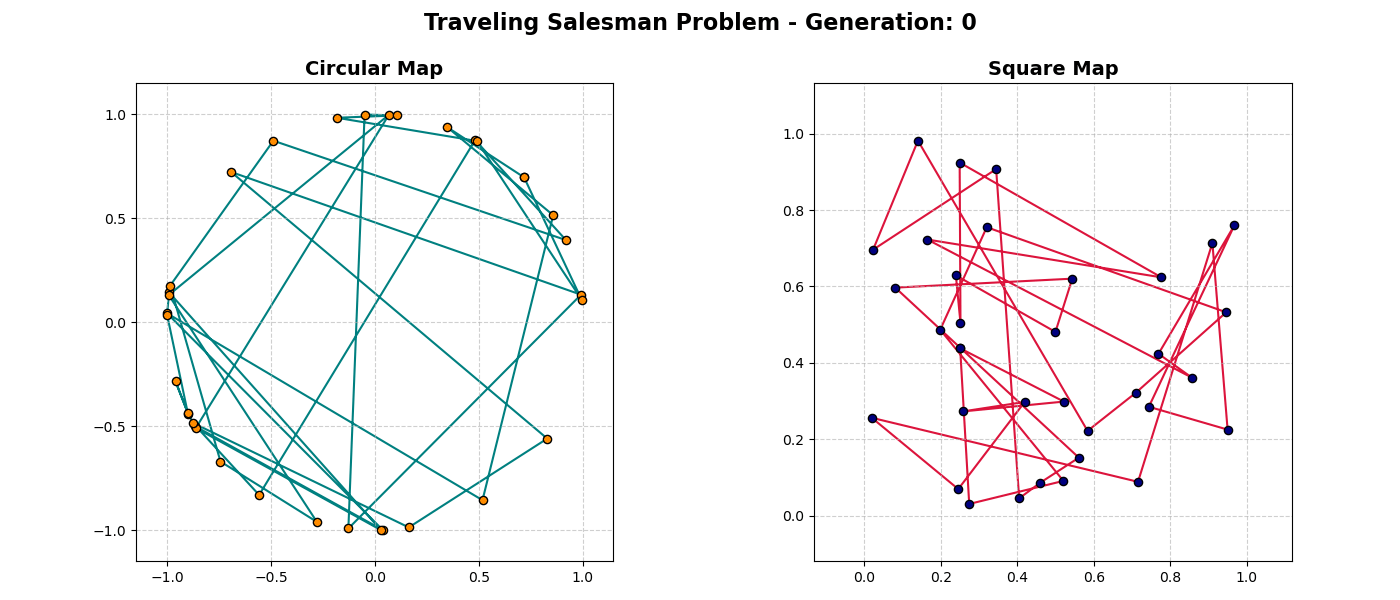

In [11]:
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image, display

data_circ = np.loadtxt("OUTPUT/circ_history.dat")
data_sq = np.loadtxt("OUTPUT/square_history.dat")

gens_circ = np.unique(data_circ[:, 0])
gens_sq = np.unique(data_sq[:, 0])

common_gens = np.intersect1d(gens_circ, gens_sq)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

line_circ, = ax1.plot([], [], color='teal', lw=1.5, zorder=1)
pts_circ = ax1.scatter([], [], color='darkorange', s=35, edgecolor='black', zorder=2)
ax1.set_title("Circular Map", fontsize=14, fontweight='bold')
ax1.set_aspect('equal')
ax1.grid(True, linestyle='--', alpha=0.6)

margin = 0.15
ax1.set_xlim(data_circ[:, 1].min() - margin, data_circ[:, 1].max() + margin)
ax1.set_ylim(data_circ[:, 2].min() - margin, data_circ[:, 2].max() + margin)

line_sq, = ax2.plot([], [], color='crimson', lw=1.5, zorder=1)
pts_sq = ax2.scatter([], [], color='navy', s=35, edgecolor='black', zorder=2)
ax2.set_title("Square Map", fontsize=14, fontweight='bold')
ax2.set_aspect('equal')
ax2.grid(True, linestyle='--', alpha=0.6)

ax2.set_xlim(data_sq[:, 1].min() - margin, data_sq[:, 1].max() + margin)
ax2.set_ylim(data_sq[:, 2].min() - margin, data_sq[:, 2].max() + margin)

title_text = fig.suptitle("", fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.95])

def update(frame_idx):
    gen = common_gens[frame_idx]
    
    mask_c = (data_circ[:, 0] == gen)
    xc, yc = data_circ[mask_c, 1], data_circ[mask_c, 2]
    line_circ.set_data(xc, yc)
    pts_circ.set_offsets(np.c_[xc, yc])
    
    mask_s = (data_sq[:, 0] == gen)
    xs, ys = data_sq[mask_s, 1], data_sq[mask_s, 2]
    line_sq.set_data(xs, ys)
    pts_sq.set_offsets(np.c_[xs, ys])
    
    title_text.set_text(f"Traveling Salesman Problem - Generation: {int(gen)}")
    return line_circ, pts_circ, line_sq, pts_sq, title_text

anim = FuncAnimation(
    fig, 
    update, 
    frames=len(common_gens), 
    interval=100, 
    blit=False
)

gif_path = "OUTPUT/tsp_evolution.gif"
anim.save(gif_path, writer=PillowWriter(fps=10))
plt.close(fig)

display(Image(filename=gif_path))

#### Hyperparameter Tuning

To identify the optimal configuration for the genetic operators, several manual calibration runs were performed across different parameter spaces:

* **Operator Probabilities:** The mutation rates (10% across all four operators), selection pressure ($p_{\text{selec}} = 2.0$), and crossover rate (70%) established in the previous simulation consistently yielded the best balance between exploratory diversity and elitist convergence.
* **Topological Sensitivity (Circle vs. Square):**
  * **Circular Map:** The algorithm converges robustly toward the theoretical minimum ($2\pi$) in virtually every run, demonstrating low sensitivity to population size due to the strictly convex nature of the optimal loop.
  * **Square Map:** In contrast, the square geometry features a rugged fitness landscape with numerous degenerate local minima. The final path length depends heavily on the interplay between population size and the number of generations. 
* **Extreme Parameter Regime:** Systematic trial-and-error revealed that reducing the genetic pool while substantially extending the evolutionary timeframe yielded the best performance for the square map. Specifically, a configuration with **$N_{\text{pop}} = 15$ individuals** evolved over **$N_{\text{gens}} = 50\,000$ generations** successfully escaped deep local traps. This setup achieved the shortest path length observed across all our tests, though we cannot rigorously confirm whether this corresponds to the true theoretical global minimum.

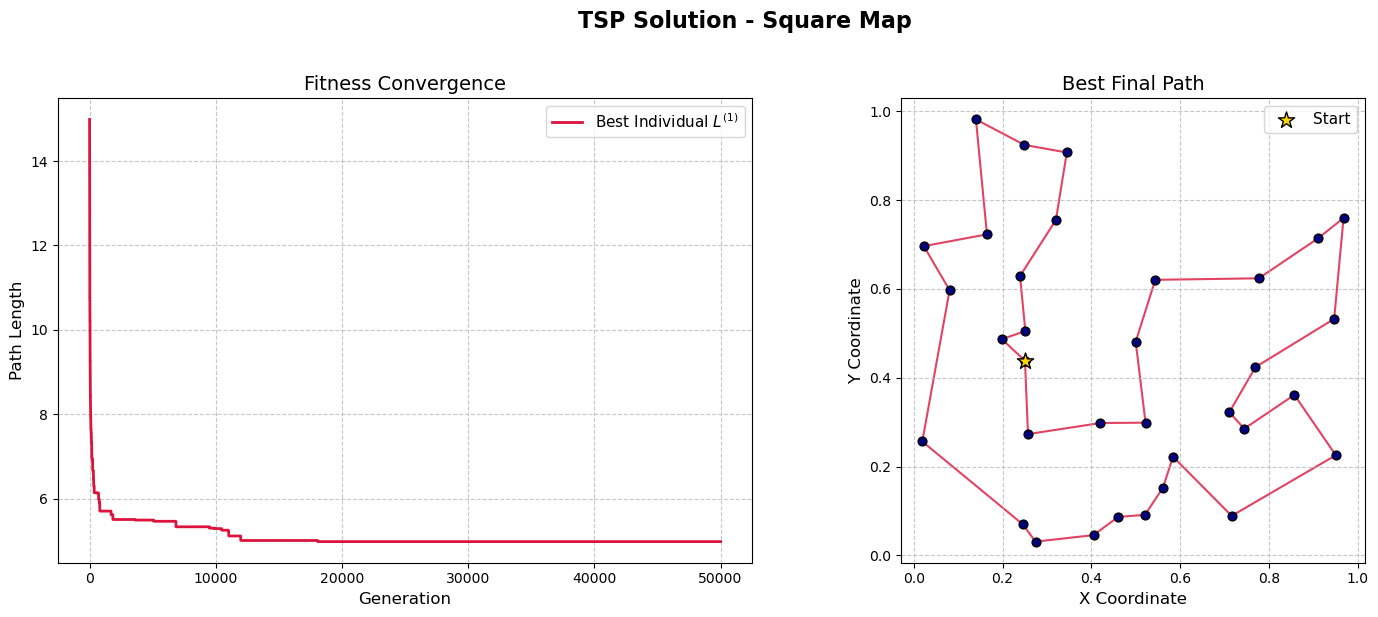

In [14]:
gen, best, mean = np.loadtxt("OUTPUT/square_output.dat", unpack=True)
x, y = np.loadtxt("OUTPUT/square_path.dat", unpack=True)

x = np.append(x, x[0])
y = np.append(y, y[0])
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle("TSP Solution - Square Map", fontsize=16, fontweight='bold', y=1.02)

ax1.plot(gen, best, label=r'Best Individual $L^{(1)}$', color='crimson', linewidth=2)
#ax1.plot(gen, mean, label=r'Best Half Mean $\langle L^{(1)} \rangle$', color='navy', linestyle='--', linewidth=2)

ax1.set_title('Fitness Convergence', fontsize=14)
ax1.set_xlabel('Generation', fontsize=12)
ax1.set_ylabel('Path Length', fontsize=12)
ax1.grid(True, linestyle='--', alpha=0.7)
ax1.legend(fontsize=11)

ax2.plot(x, y, color='crimson', linewidth=1.5, alpha=0.8, zorder=1)
ax2.scatter(x, y, color='navy', s=40, zorder=2, edgecolor='black')

ax2.scatter(x[0], y[0], color='gold', marker='*', s=150, edgecolor='black', zorder=3, label='Start')

ax2.set_title('Best Final Path', fontsize=14)
ax2.set_xlabel('X Coordinate', fontsize=12)
ax2.set_ylabel('Y Coordinate', fontsize=12)
ax2.set_aspect('equal')
ax2.grid(True, linestyle='--', alpha=0.7)
ax2.legend(fontsize=11)

plt.tight_layout()
plt.show()

By visually comparing the final paths obtained from the two different configurations for the square map, it becomes explicitly clear that the standard setup ($N_{\text{pop}} = 200$, $N_{\text{gens}} = 200$) was trapped in a local minimum. 

The two routes are visibly distinct: the path generated by the 200/200 configuration does not present random tangles or intersections, but rather a clean, structurally stable, yet sub-optimal routing sequence through the central cities. The algorithm prematurely converged, locking the population into a sequence that is simply longer than the true optimum. In contrast, the extensive run ($N_{\text{pop}} = 15$, $N_{\text{gens}} = 10\,000$) maintained enough exploratory capability to discover alternative macroscopic connections, finding a more optimized sequence and confirming that the previous simulation had halted at a higher energy valley.